# 20. From photographs to a static scene

[Course plan](../../README.md)

Nine photographs of a sculpture are on the table. Their camera poses are known. One image can stay face down while the other eight guide the fit. Turning it over at the end shows what the model managed to learn about the space between cameras.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'en'

import photo_diagnostics as inspect_photo

## The starting point

The colored-splat experiment starts with known centers and sizes. All splats are gray. Each color step sees three training views together. In the photographic capture, the centers come from sparse reconstruction. Changing the selected camera shows another image of the same model. A sideways camera shift opens a further view without a reference photograph. The browser fits RGB with geometry fixed. Later in the Python calculation, centers, three widths, rotation and opacity also become trainable.


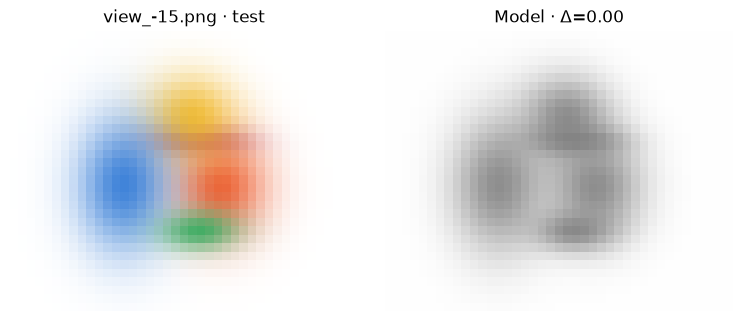

In [2]:
frames, initial = synthetic_capture()
def small_view(steps, offset):
    model, _ = fit_colors(initial, frames, int(steps))
    return view_figure(frames, model, 1, offset, lang)
display(small_view(0,0)); plt.close()
controls(small_view, steps=(0,24,1,0), offset=(-.2,.2,.005,0))


## From one pixel to a first step

We can follow just the red channel. A splat starts at $c=0.5$. In this pixel its compositing weight is $w=T\alpha=0.6$. White background fills the remaining 0.4. The prediction is $P=0.6\cdot0.5+0.4\cdot1=0.7$. The photograph gives $Y=0.58$. The residual $P-Y=0.12$ has square $0.0144$. Adding 0.01 to the red channel would increase $P$ by $0.6\cdot0.01=0.006$. The current red is already too bright.

The derivative of squared error with respect to this color is $2(P-Y)w$. The 2 comes from the square, the residual retains its sign, and $w$ measures how much of the ray can see this splat. Numerically this is $2\cdot0.12\cdot0.6=0.144$. At learning rate 0.5, the new value is $0.5-0.5\cdot0.144=0.428$. Now $P=0.6568$ and the squared residual is about $0.00590$. The full calculation combines pixels from all training views. Empty areas carry little information about a particular splat.

Why are these first steps cheap? Fixed shapes give fixed weights. For pixel $j$ we store $w_{ji}$, its weight from visible splat $i$, and $b_j$, its fraction of white background. Then $P_j=b_j+\sum_i w_{ji}c_i$. The sum adds each splat’s contribution. With weights 0.6 and 0.1, background 0.3 and colors 0.5 and 0.2, the prediction is $0.3+0.6\cdot0.5+0.1\cdot0.2=0.62$. Each weight-matrix column corresponds to a splat and each row to a pixel. Summed products of these weights can be prepared just once, so another RGB update avoids reprojection. Each channel stays between 0 and 1.


In [3]:
w,c,b,target = .6,.5,.4,.58
pred = b+w*c
updated = c-.5*2*(pred-target)*w
print("color:", c, "→", updated)
print("loss:", (pred-target)**2, "→", (b+w*updated-target)**2)
assert (b+w*updated-target)**2 < (pred-target)**2


color: 0.5 → 0.428
loss: 0.0144 → 0.005898240000000014


## Two different pairs of splats can make the same pixel

From the front, the first splat supplies a weight of 0.6 and the second supplies 0.1. White background accounts for 0.3. Suppose their red channels are 0.4 and 0.8. The pixel receives $0.6\cdot0.4+0.1\cdot0.8+0.3=0.62$. A different pair of colors, 0.45 and 0.5, gives exactly the same result. The first splat added $0.6\cdot0.05=0.03$ and the second took away $0.1\cdot0.3=0.03$. This camera has no evidence for choosing between the pairs.

From the side, the splats overlap differently. Their weights are now 0.2 and 0.5, with 0.3 still left for the background. The first pair predicts 0.78 and the second predicts 0.64. The side photograph measures 0.78. That is what the new camera brought to the fit: a measurement that **mixes the same two unknowns in different proportions**.

Starting with gray $(0.5,0.5)$, both cameras predict 0.65. The signed residuals are $+0.03$ and $-0.13$. Their mean square is $(0.03^2+0.13^2)/2=0.0089$. What if the first splat gets a little redder? The front pixel receives 0.6 times the increment and the side pixel receives 0.2 times the increment. The derivative of the mean square is $0.6\cdot0.03+0.2\cdot(-0.13)=-0.008$. The factor of two from the square cancels the division by two measurements. For the second splat the result is $0.1\cdot0.03+0.5\cdot(-0.13)=-0.062$. A small increase helps in both cases; the second splat receives a much stronger signal.

In the code, `W` holds two rows of weights. `W @ colors` assembles two pixels. `W.T @ residual` sends their errors back to the two splats. With fixed geometry, $W^\mathsf{T}(Wc-y)$ expands to $(W^\mathsf{T}W)c-W^\mathsf{T}y$. Here $y$ is the measured channel minus the background contribution. The two tables that contain no $c$ can be computed once. They appear as `gram` and `rhs` in `fit_colors`. Moving a center changes the weights, so the old table no longer describes the image.

<details><summary>What if the second picture is a copy of the first?</summary>

The two weight rows coincide. Repeating an exposure may average away measurement noise, but the two proposed color pairs still cannot be told apart. In the limiting case, a splat is hidden in every view. Its entire column of weights is zero, so changing its color leaves no trace in the pictures.

</details>

In [4]:
W = np.array([[.6,.1], [.2,.5]])
background = np.array([.3,.3])
red = np.array([.5,.5])
observed = np.array([.62,.78])
def two_view_loss(red):
    return np.mean((W @ red + background - observed)**2)
gradient = W.T @ (W @ red + background - observed)
eps = 1e-5
measured = [(two_view_loss(red+eps*d)-two_view_loss(red-eps*d))/(2*eps) for d in np.eye(2)]
print("∂L/∂c:", gradient, "  ΔL/Δc:", np.round(measured,6))
assert np.allclose(gradient, measured)
assert np.allclose(np.linalg.solve(W, observed-background), [.4,.8])

∂L/∂c: [-0.008 -0.062]   ΔL/Δc: [-0.008 -0.062]


## A capture that travels with the model

Now the targets are real photographs from **PhysicalAI-NuRec-PPISP, struktur28_auto, NVIDIA Corporation, CC BY 4.0**. The course subset contains nine undistorted, adapted 160 × 120 images. Eight training photographs supplied 117 triangulated points at known camera poses. The ninth image’s pixels supplied neither those point locations nor their colors. For a quick fit we start from 24 points and reduce the images to 40 × 30. The initial splats are gray with equal opacity. A larger cloud can carry finer details at higher cost per step. [Photograph provenance and adaptations](https://github.com/HeinrichWirth/gaussian-splatting-course/tree/main/data/photographic-example)

Under the notebook's working directory, `static-scene-result/capture/` holds the PNGs, cameras, initial parameters and train/test labels. The neighboring file `static-scene-result/capture-browser.json` packs the capture for the website. After fitting, `static-scene-result/static-gaussians.json` contains the fitted parameters. The read-back check prints the model path relative to the working directory. In the notebook, `model_path.resolve()` returns the full local path including the filename.

For a separate capture, only the first line of the experiment below needs to change, where `photos, seed` are assigned. Suppose `IMG_0012.jpg` is the held-out photograph in that capture, processed with COLMAP as in lesson 19. With the `capture` folder in the working directory, the input becomes

```python
photos, seed = load_colmap(
    Path("capture/text"), Path("capture/undistorted/images"),
    max_side=40, max_points=24, test_names=["IMG_0012.jpg"],
)
```

The name must match its entry in `images.txt`, including its extension and any subdirectories. A held-out image amid near-identical burst shots tells little about a genuinely new view. The limits of 40 pixels and 24 splats keep the same image and model budgets as in the sculpture experiment.

When a personal reconstruction was estimated from all photographs, the loader split excludes held-out RGB from the gradients. Its initial 3D points and poses may still depend on held-out features. A stricter evaluation triangulates the initial cloud from training observations alone and supplies the test pose separately. The included example separates pixels and tracks that way, with original camera calibration supplied for the entire capture.

In [5]:
photos, seed = photo_capture(max_side=40, max_points=24)
out = Path.cwd() / "static-scene-result"
write_capture(out/"capture", photos, seed)
photos, seed = read_capture(out/"capture")
export_browser_capture(photos, seed, out/"capture-browser.json")
warm, color_loss = fit_colors(seed, photos, steps=12)
print("views:", len(photos), "splats:", len(seed["splats"]))
print("train RGB MSE:", round(color_loss[0],6), "→", round(color_loss[-1],6))


views: 9 splats: 24
train RGB MSE: 0.336137 → 0.25423


## Why color alone leaves a gray cloud unfinished

If a splat lands to the left of a stone edge, changing its hue cannot move it. The calculation now has a longer chain. Its 3D center moves into camera coordinates; dividing by depth gives the screen position. Shape and orientation determine the projected covariance. Each pixel gets a weight and transmittance, then RGB, a difference from the photograph and its square. PyTorch traces that chain backward. Every camera sees **the same** scene parameters. Each update first averages errors within a frame and then across the eight training frames.

The three widths must stay positive. We store unrestricted numbers $\ell$ and render the widths $s=\exp(\ell)$. At $\ell=0$, width is 1. At $\ell=-0.6931$, it is about 0.5 scene units. For opacity and color we store $a$ and render $1/(1+\exp(-a))$. At $a=0$ this gives $1/(1+1)=0.5$. Negative inputs move the output toward zero and positive inputs toward one. The four rotation coordinates are divided by their joint length as in lesson 12. Every update therefore yields a valid shape.

The single-color example used an ordinary gradient step. Across the different scene parameters below, Adam tracks an average direction and recent squared gradient magnitudes. Where one parameter repeatedly gives large gradients, normalization reduces its relative update. The code’s 0.017 sets the overall scale. This fit keeps 30 steps and a budget of 24 splats. Directional appearance, density changes and richer losses enter the larger implementation. The small experiment isolates the passage from sparse points to an adjustable image.


saved: static-scene-result/static-gaussians.json  RGB MSE: 0.25423 → 0.056428


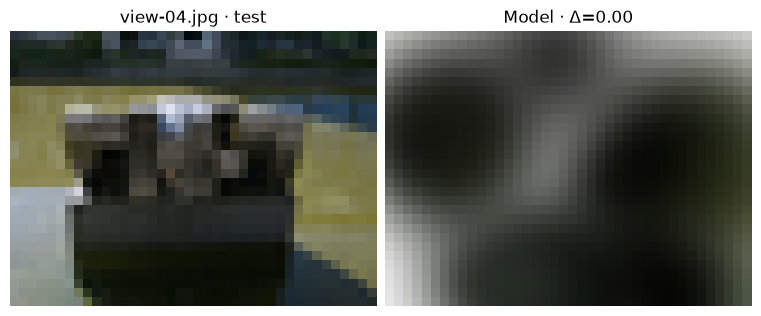

In [6]:
import torch
from reconstruction_fit import refine_scene
torch.set_num_threads(1)
trained, fit_loss = refine_scene(warm, photos, steps=30, rate=.017)
model_path = out/"static-gaussians.json"
model_path.write_text(json.dumps(trained, indent=2, allow_nan=False), encoding="utf8")
opened = json.loads(model_path.read_text(encoding="utf8"))
test_index = next(i for i,f in enumerate(photos) if f["split"]=="test")
f = photos[test_index]
h,w = f["rgb"].shape[:2]
assert np.allclose(render_scene(opened,f["camera"],w,h),render_scene(trained,f["camera"],w,h))
print("saved:", model_path.relative_to(Path.cwd()).as_posix(), " RGB MSE:", round(fit_loss[0],6), "→", round(fit_loss[-1],6))
display(view_figure(photos, opened, test_index, lang=lang)); plt.close()


## What changed in thirty steps?

The sculpture lets us keep three versions of **the same 24 splats**. In the first they are gray. The second has had 12 steps of color fitting. The third starts from the second and takes 30 more steps, this time changing color, geometry and opacity together. The three pictures below all use the held-out camera at 40 × 30. Switching viewpoints, splat budgets or resolution between columns would spoil the comparison.

Across the eight training images the mean squared error goes from about 0.3361 to 0.2542 after fitting color, then to 0.0564 after the joint fit. On the held-out view the corresponding values are 0.3501, 0.2652 and 0.0512. The improvement carried over at least as far as this camera. An angle absent from the capture contributes no evidence to the comparison.

Why does freeing the shapes make such a difference? A gray splat on white has a limit. At a pixel where its weight is 0.2, even a black splat produces $0.2\cdot0+0.8\cdot1=0.8$. No color update can reach a dark patch measuring 0.18. Moving the center, widening the footprint or raising opacity can increase the weight. They have different consequences for neighboring pixels: a shift moves an edge, widening spreads coverage on both sides, and higher opacity also conceals deeper layers. A single ray often cannot distinguish the causes.

Initial {'train': np.float64(0.33614), 'test': np.float64(0.35014)}
RGB only {'train': np.float64(0.25423), 'test': np.float64(0.26525)}
All parameters {'train': np.float64(0.05643), 'test': np.float64(0.05124)}


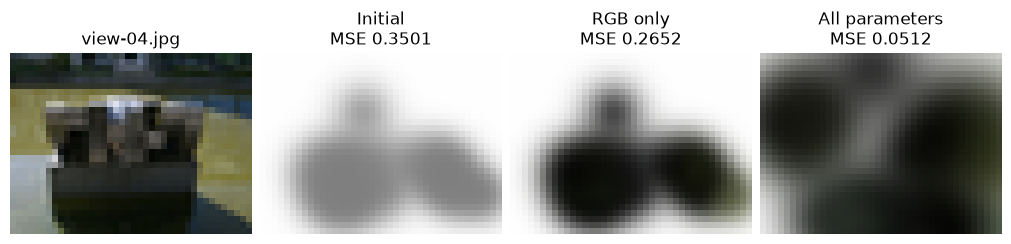

In [7]:
stages = [seed, warm, opened]
labels = ["Старт", "Только RGB", "Все параметры"] if lang=="ru" else ["Initial", "RGB only", "All parameters"]
fig, axes = plt.subplots(1,4,figsize=(10,3),layout="constrained")
axes[0].imshow(f["rgb"]); axes[0].set_title(f["name"])
for ax, model, title in zip(axes[1:], stages, labels):
    pred = render_scene(model,f["camera"],w,h)
    ax.imshow(pred)
    ax.set_title(f"{title}\nMSE {np.mean((pred-f['rgb'])**2):.4f}")
    print(title, {split:round(np.mean([row["mse"] for row in evaluate(model,photos,split)]),5)
                  for split in ("train","test")})
for ax in axes: ax.axis("off")
plt.show()

## What the viewer opens

**static-gaussians.json** stores three center coordinates, three scales, four rotation coordinates, three color channels and one opacity per splat. Camera data stays with the capture because an image depends on both the scene and the observer. In the web lab, `capture-browser.json` goes into the local JSON field first, followed by `static-gaussians.json` in the same field. The browser uses the capture’s cameras to draw the imported model. A held-out photo can be compared with its render before shifting the camera. At a new pose the error readout disappears because there is no corresponding measurement. The browser accepts 2 to 32 frames, including at least one training and one held-out frame, up to 128 × 128 pixels per frame, and up to 128 splats. There is also a cap on the total computation size of a capture. A larger shoot can stay in Python while a selection of its cameras goes into the viewer. Both files stay on the device.

The website opens on the held-out photograph. Its dataset menu also offers **“Trained sculpture · 117 splats”**. This model ran for 1,200 steps on the same eight views, sampling 256 training pixels per step. It opens directly for inspection and export. At full evaluation resolution, 80 × 60, its MSE on view-04 is about 0.00982 or 20.08 dB. The browser compares this trained scene with the same 80 × 60 photograph. [Training the 117-splat model](https://github.com/HeinrichWirth/gaussian-splatting-course/blob/main/scripts/train_photo_reference.py)

Does the model resolve the stone’s details? Its splat budget is small, training directions are limited, and color is constant across viewpoints. Large masses and background color can emerge while narrow edges go missing. The next lesson measures that gap.


In [8]:
controls(lambda view, offset: view_figure(photos, opened, int(view), offset, lang),
         view=list(range(len(photos))), offset=(-.2,.2,.01,0))
print("model file:", model_path.name, " capture file: capture-browser.json")


model file: static-gaussians.json  capture file: capture-browser.json


## Which splats painted this pixel of the sculpture?

This time the scene contains 117 splats. At column 40, row 30 of view-04 the photograph has RGB about $(0.180,0.180,0.161)$. To find where the render got its slightly different shade, we can follow the ray in depth order and record two quantities at each splat: how much visibility reached it ($T$) and which fraction of that remainder it covers ($\alpha$).

Splat 25 gives $T\alpha\approx1.0000\cdot0.4726=0.4726$. Only 0.4843 reaches splat 102. Its own pixel opacity is larger, 0.7529, but its share is smaller: $0.4843\cdot0.7529\approx0.3646$. The list below the photograph is sorted **by contribution**, after the depth traversal. The other splats and 0.0543 of white background complete the two leading weights. All weights together sum to one. Multiplying each by its RGB gives the final mixture $(0.164,0.167,0.151)$.

With geometry frozen, increasing just the red channel of splat 25 by 0.01 raises this pixel’s red by $0.4726\cdot0.01=0.004726$. The photograph was redder, so the change would help here. At the top left, splat 13 takes the lead and splat 25 carries only about 0.112 of the pixel. The same edit raises red there by just 0.00112. The decision to apply an update depends on all the training pixels. Here view-04 is a way to examine the already fitted model.

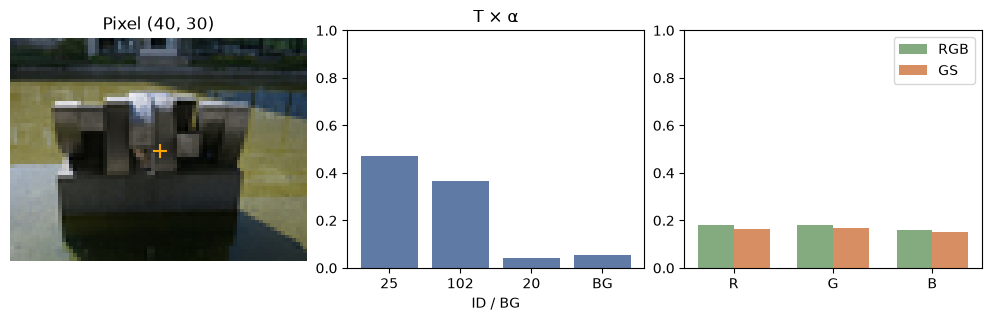

In [9]:
detail_model, detail_frame = inspect_photo.reference_photo()
def inspect_pixel(u,v):
    return inspect_photo.pixel_figure(detail_model,detail_frame,u,v,lang)
display(inspect_pixel(40,30)); plt.close()
controls(inspect_pixel,u=(0,79,1,40),v=(0,59,1,30))

## The same photographs in the authors’ implementation

A full-size run uses the official project’s dedicated CUDA environment, rasterizer extension and a compatible NVIDIA GPU. The commands run inside the installed reference implementation and reuse **the undistortion results** from lesson 19. The files from `capture/undistorted/images` go in `scene/images`. The contents of `capture/undistorted/sparse`, including binary cameras.bin, images.bin and points3D.bin, go in `scene/sparse/0`. Image filenames continue to match the names in the model. The teaching loader reads the text export; the authors’ implementation uses the binary files.

```sh
python train.py -s scene -m models/sculpture --eval
python render.py -m models/sculpture
python metrics.py -m models/sculpture
SIBR_gaussianViewer_app -m models/sculpture
```

SIBR here is the installed viewer executable in the authors’ bin directory, with an .exe extension on Windows. The `-m` argument points at the **model directory** containing settings and the saved cloud in point_cloud/iteration_…/point_cloud.ply. Its PLY schema and parameterization differ from the teaching JSON. The official trainer changes density and learns spherical-harmonic appearance. With `--eval`, the ordinary COLMAP split holds out every eighth image in filename order. Our experiment explicitly reserves view-04. Comparing the two runs requires the same test poses, resolution and background. [Official project and dependencies](https://github.com/graphdeco-inria/gaussian-splatting) · [Image split implementation](https://github.com/graphdeco-inria/gaussian-splatting/blob/main/scene/dataset_readers.py)

## An experiment

After saving the scene, the camera moves. Which numbers in the Gaussian file must change?

<details><summary>Worked answer</summary>

None. The renderer recomputes pixel positions, footprints and depth order. Training changes the stored scene; navigating a trained scene moves the observer.

</details>


## When a new capture turns into a white cloud

<details><summary>The loss barely moves. How can an empty projection be distinguished from a bad color?</summary>

One training camera is enough to overlay a handful of initial centers on its photograph and examine their depths. Negative depths for points in front of the camera suggest a pose conversion or axis error. Centers on the subject at the correct image resolution, yet nearly pure background in the middle of it, tell a different story. Temporarily doubling the width of one splat is a small diagnostic experiment. If its footprint appears on the expected detail, coverage or initial opacity deserves attention. If the footprint lands somewhere else, widening the entire cloud would mask the problem. The edit is reversible and it separates two explanations.

</details>

<details><summary>The training edges look sharp, but a patch detaches from the side. What makes the problem reproducible?</summary>

The named photographs with poses, fitting-view list, initial scene, fitted scene and the camera where the defect appears all matter. Replaying one short camera movement before and after the joint fit shows whether the patch was already present in the sparse cloud. Projecting a suspect point into several training photographs helps distinguish a bad initial track from a splat that drifted during fitting. If the scene looks convincing only in familiar views, an independent viewpoint supplies the next piece of evidence. Lesson 21 follows the score and the spatial pattern of that error.

</details>